In [1]:
import yaml
import warnings
import sys

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as pl
import seaborn as sns
import PyComplexHeatmap as pch
from pathlib import Path
from tqdm.auto import tqdm

from sklearn.metrics import roc_curve, roc_auc_score
from matplotlib.cm import get_cmap

# make figures paper quality
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = 'Arial'

# Remove warning, we like to live dangerously
warnings.filterwarnings("ignore")

# load functions from ../utils
sys.path.append('../utils')
from utils import get_nnmd, annotate_essentiality

# Get config settings
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)
cell_line_dict=config['cell_lines']
cell_line_colors=config['cell_line_colors']

In [2]:
# counts
df = pd.read_csv(Path(config['TEMPDIR']) / 'SYM101_counts_corrected.csv', index_col=0)
sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
controls = [x for x in df.index if 'control' in x.lower()]
# essential genes
essential = pd.read_csv("../resources/bagel_supplement/CEGv2.txt", sep='\t', index_col=0)
non_essential = pd.read_csv("../resources/bagel_supplement/NEGv1.txt", sep='\t', index_col=0)

In [3]:
# THIS IS ONLY TP6!
gene_cdf = pd.read_csv('../results/merged/gene_results_perline.csv', index_col=0, header=[0,1])
gene_cdf = gene_cdf[gene_cdf.index!='NT_Control']  # remove control
final_gene_list = pd.read_csv('../resources/symp_101_final_gene_list.csv', index_col=0)
gene_cdf['is_final'] = gene_cdf.index.isin(final_gene_list.index)
gene_cdf['essentiality'] = annotate_essentiality(gene_cdf.index)

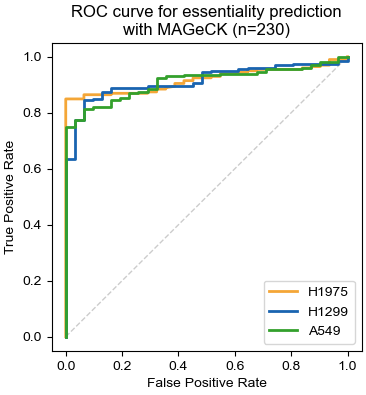

In [ ]:
fig, ax = pl.subplots(figsize=(4, 4))
data = {}
for cell_line in cell_line_dict.values():
    if cell_line in ['SYM4', 'SYM5']:
        continue
    essentiality_known = gene_cdf.essentiality != 'unknown'
    fpr, tpr, thresholds = roc_curve(gene_cdf.essentiality[essentiality_known] == 'essential', -gene_cdf.loc[essentiality_known, (cell_line, 'MAGeCK_filtered_score')])
    data[cell_line] = (fpr, tpr)
    ax.plot(fpr, tpr, label=cell_line, linewidth=2, color=cell_line_colors[cell_line])
ax.legend()
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title(f'ROC curve for essentiality prediction\nwith MAGeCK (n={int(sum(essentiality_known))})')
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1, zorder=-1, alpha=0.4)
pl.savefig('../results/figures/MAGECK_ROC_curve_essentiality_prediction.pdf', bbox_inches='tight')
pd.DataFrame(data, index=['FPR', 'TPR']).T.to_csv('../results/source_tables/Fig1d_source_data.csv')
pl.show()

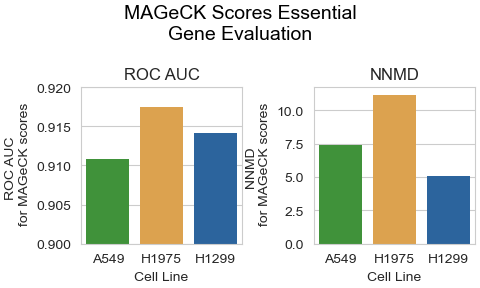

In [ ]:
# AUC scores
from sklearn.metrics import roc_auc_score
aucs = {}
nnmds = {}
for line in ['A549', 'H1299', 'H1975']:
    sdf = gene_cdf.loc[:, (line, slice(None, None, None))]  # get all entries
    # now remove the multi-index
    sdf.columns = sdf.columns.droplevel([0])
    sdf['essentiality'] = gene_cdf['essentiality']

    mask = sdf.essentiality!='unknown'
    sdf['negative_score'] = -sdf['MAGeCK_filtered_score']
    aucs[(line)] = roc_auc_score(sdf[mask].essentiality=='essential', sdf[mask].negative_score)
    nnmds[(line)] = get_nnmd(sdf, score_column='negative_score')
auc_df = pd.DataFrame(aucs, index=['AUC']).T.reset_index().rename(columns={'index':'line'})
nnmd_df = pd.DataFrame(nnmds, index=['NNMD']).T.reset_index().rename(columns={'index':'line'})

with sns.axes_style('whitegrid'):
    fig, axs = pl.subplots(1, 2, figsize=(2.5*2,3))
ax = axs[0]
sns.barplot(data=auc_df, x='line', y='AUC', ax=ax, hue='line', palette=cell_line_colors, order=['A549', 'H1975', 'H1299'])
ax.set_xlabel('Cell Line')
ax.set_ylabel('ROC AUC \n for MAGeCK scores')
ax.set_ylim(0.9,0.92)
ax.set_title('ROC AUC')

ax = axs[1]
sns.barplot(data=nnmd_df, x='line', y='NNMD', ax=ax, hue='line', palette=cell_line_colors, order=['A549', 'H1975', 'H1299'])
ax.set_xlabel('Cell Line')
ax.set_ylabel('NNMD \n for MAGeCK scores')
ax.set_title('NNMD')

pl.suptitle('MAGeCK Scores Essential\nGene Evaluation', fontsize=14)
pl.tight_layout()

pd.concat([auc_df.set_index('line'), nnmd_df.set_index('line')], axis=1).to_csv('../results/source_tables/SuppFig1c_source_data.csv')
pl.savefig(f'../results/figures/MAGECK_based_ROCAUC_and_NNMD_SYM101.pdf', bbox_inches='tight', dpi=300)
pl.show()

### Comparison with previous Cas9 data

In [ ]:
# TODO: think about how to scale these.

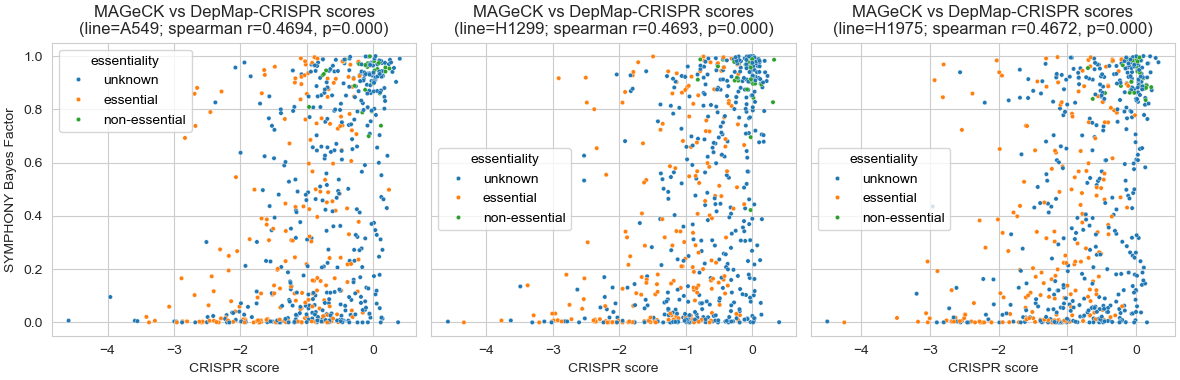

In [95]:
with sns.axes_style('whitegrid'):
    fig, axs = pl.subplots(1, 3, figsize=(4*3,4), sharey=True)
for i, line in enumerate(['A549', 'H1299', 'H1975']):
    ax = axs[i]
    sdf = gene_cdf.loc[:, (line, slice(None, None, None))]  # get all entries
    # now remove the multi-index
    sdf.columns = sdf.columns.droplevel([0])

    # Annotate
    sdf['essentiality'] = gene_cdf['essentiality']
    gene_data = pd.read_csv('../resources/symp_101_final_gene_list.csv', index_col=0)
    sdf = pd.merge(sdf, gene_data, left_index=True, right_index=True, how='left')
    
    cl_name = f'NCI{line}' if line!='A549' else line
    
    sns.scatterplot(data=sdf, y='MAGeCK_filtered_score', x=f'{cl_name}_Crs', hue='essentiality', s=10, ax=ax)
    # add spearman correlation
    from scipy.stats import spearmanr
    r, p = spearmanr(sdf['MAGeCK_filtered_score'].values, sdf[f'{cl_name}_Crs'].values, nan_policy='omit')
    ax.set_xlabel('CRISPR score')
    ax.set_ylabel('SYMPHONY Bayes Factor')
    ax.set_title(f'MAGeCK vs DepMap-CRISPR scores\n(line={line}; spearman r=%.4f, p=%.3f)' % (r, p))
pl.tight_layout()
# pl.savefig(f'../results/bagel2/bagel2_vs_crispr{name}.pdf', bbox_inches='tight', dpi=300)
pl.show()

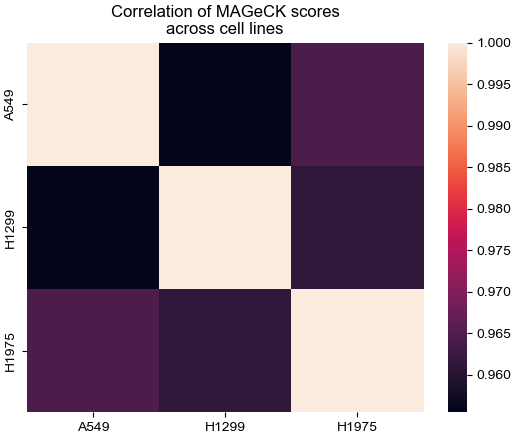

In [60]:
sdf = gene_cdf.xs('MAGeCK_filtered_score', level=1, axis=1)
sns.heatmap(sdf.corr(method='pearson'))
pl.title('Correlation of MAGeCK scores\nacross cell lines')
pl.savefig(f'../results/figures/MAGeCK_line_correlation.pdf', bbox_inches='tight', dpi=300)
pl.show()

# MAGeCK

## Guide Ranking, Filtering

- Look for highest MAGeCK score and absLFC across cell lines
- Set threshold for filtering to XXth percentile of max score in NT guides
- Mark all guides with less score than threshold as "filtered out"

In [6]:
all_guide_rankings = pd.concat({cell_line: pd.read_csv(f'../results/mageck/summaries/{cell_line}/gene_pooled_screen_1_counts_mageck.sgrna_summary.txt', sep='\t', index_col=0) for cell_line in cell_line_dict.values()}, axis=1)
# aggregate
all_guide_rankings[('summary', 'max_score')] = all_guide_rankings.loc[:, (slice(None), 'score')].max(axis=1)
all_guide_rankings[('summary', 'mean_score')] = all_guide_rankings.loc[:, (slice(None), 'score')].mean(axis=1)
all_guide_rankings[('summary', 'min_score')] = all_guide_rankings.loc[:, (slice(None), 'score')].min(axis=1)
all_guide_rankings[('summary', 'max_LFC')] = all_guide_rankings.loc[:, (slice(None), 'LFC')].max(axis=1)
all_guide_rankings[('summary', 'mean_LFC')] = all_guide_rankings.loc[:, (slice(None), 'LFC')].mean(axis=1)
all_guide_rankings[('summary', 'min_LFC')] = all_guide_rankings.loc[:, (slice(None), 'LFC')].min(axis=1)
all_guide_rankings[('summary', 'absmax_LFC')] = np.abs(all_guide_rankings.loc[:, (slice(None), 'LFC')]).max(axis=1)
all_guide_rankings[('summary', 'is_control')] = all_guide_rankings.index.str.contains('Control').astype(str)

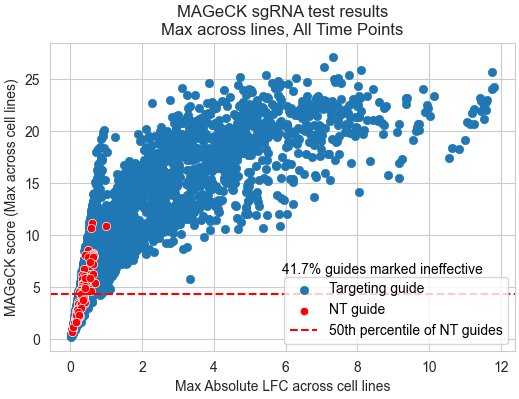

In [8]:
data = all_guide_rankings.loc[:, 'summary']
data_control = data[(data.is_control=='True')]

y_key = 'max_score'
p = 50

with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots(figsize=(6,4))

sns.scatterplot(data=data, x='absmax_LFC', y=y_key, edgecolor=None, label='Targeting guide')
sns.scatterplot(data=data_control, x='absmax_LFC', y=y_key, color='red', label='NT guide')

tresh = np.percentile(data_control[y_key], p)
pl.axhline(tresh, color='r', linestyle='--', label=f'{p}th percentile of NT guides')
percent_removed = ((data[y_key]<tresh) & (data.is_control=='False')).mean()
pl.text(0.5, 0.25, f'{percent_removed:.1%} guides marked ineffective', transform=pl.gca().transAxes)
pl.title('MAGeCK sgRNA test results\nMax across lines, All Time Points')
pl.ylabel('MAGeCK score (Max across cell lines)')
pl.xlabel('Max Absolute LFC across cell lines')
pl.legend()
pl.show()

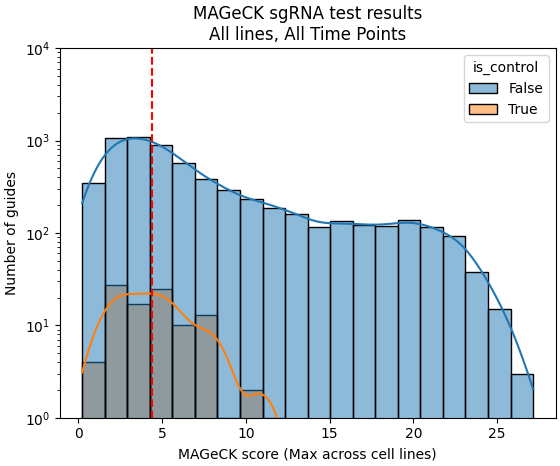

In [5]:
sns.histplot(data=data, x='max_score', bins=20, kde=True, hue='is_control')
pl.axvline(tresh, color='r', linestyle='--', label=f'{p}th percentile of controls')
pl.yscale('log')
pl.ylim(1, 1e4)
pl.ylabel('Number of guides')
pl.xlabel('MAGeCK score (Max across cell lines)')
pl.title('MAGeCK sgRNA test results\nAll lines, All Time Points')
pl.show()

In [6]:
# annotate
all_guide_rankings[('summary', 'is_working')] = all_guide_rankings.loc[:, 'summary'].max_score>tresh

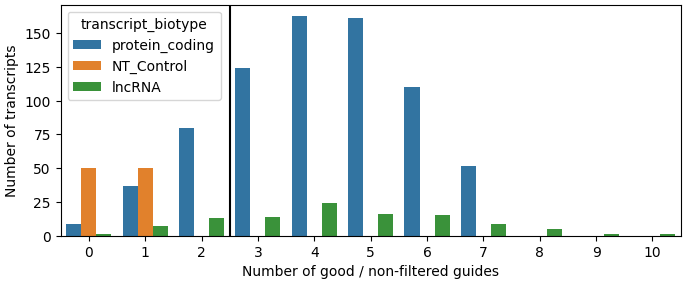

In [90]:
# How many guides are marked per target?
data = all_guide_rankings.loc[:, 'summary']
# add infos
df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)
for col in ['Gene', 'Transcript_ID', 'transcript_biotype', 'Region']:
    data[col] = df.loc[data.index, col]
# counting
sdf = data.groupby(['Transcript_ID', 'transcript_biotype'], observed=False).sum().is_working.reset_index()
sdf = sdf[(sdf.transcript_biotype.isin(['protein_coding', 'lncRNA', 'NT_Control']))]
sdf.rename(columns={'is_working':'good_guides_count'}, inplace=True)

pl.figure(figsize=(8,3))
sns.barplot(data=sdf.value_counts(['transcript_biotype', 'good_guides_count']).reset_index(),
            x='good_guides_count', y=0, hue='transcript_biotype')
pl.xlabel('Number of good / non-filtered guides')
pl.ylabel('Number of transcripts')
pl.axvline(2.5, color='k')
pl.show()

In [93]:
# filtering would remove too many guides for these target, so we enforce keeping at least 3 guides
N = 3
key = 'keep_flag'
too_few = sdf.loc[sdf.good_guides_count<N, 'Transcript_ID']
print(len(too_few))

data = all_guide_rankings.loc[:, 'summary']
# add infos
df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)
for col in ['Gene', 'Transcript_ID', 'transcript_biotype', 'Region']:
    data[col] = df.loc[data.index, col]
keep = data[data.Transcript_ID.isin(too_few)].groupby('Transcript_ID').max_score.nlargest(N).index.get_level_values(1)
all_guide_rankings.loc[:, ('summary', key)] = all_guide_rankings.loc[:, ('summary', 'is_working')].copy()
all_guide_rankings.loc[df.loc[all_guide_rankings.index].Transcript_ID.isin(too_few), ('summary', key)] = False
all_guide_rankings.loc[keep, ('summary', key)] = True

247


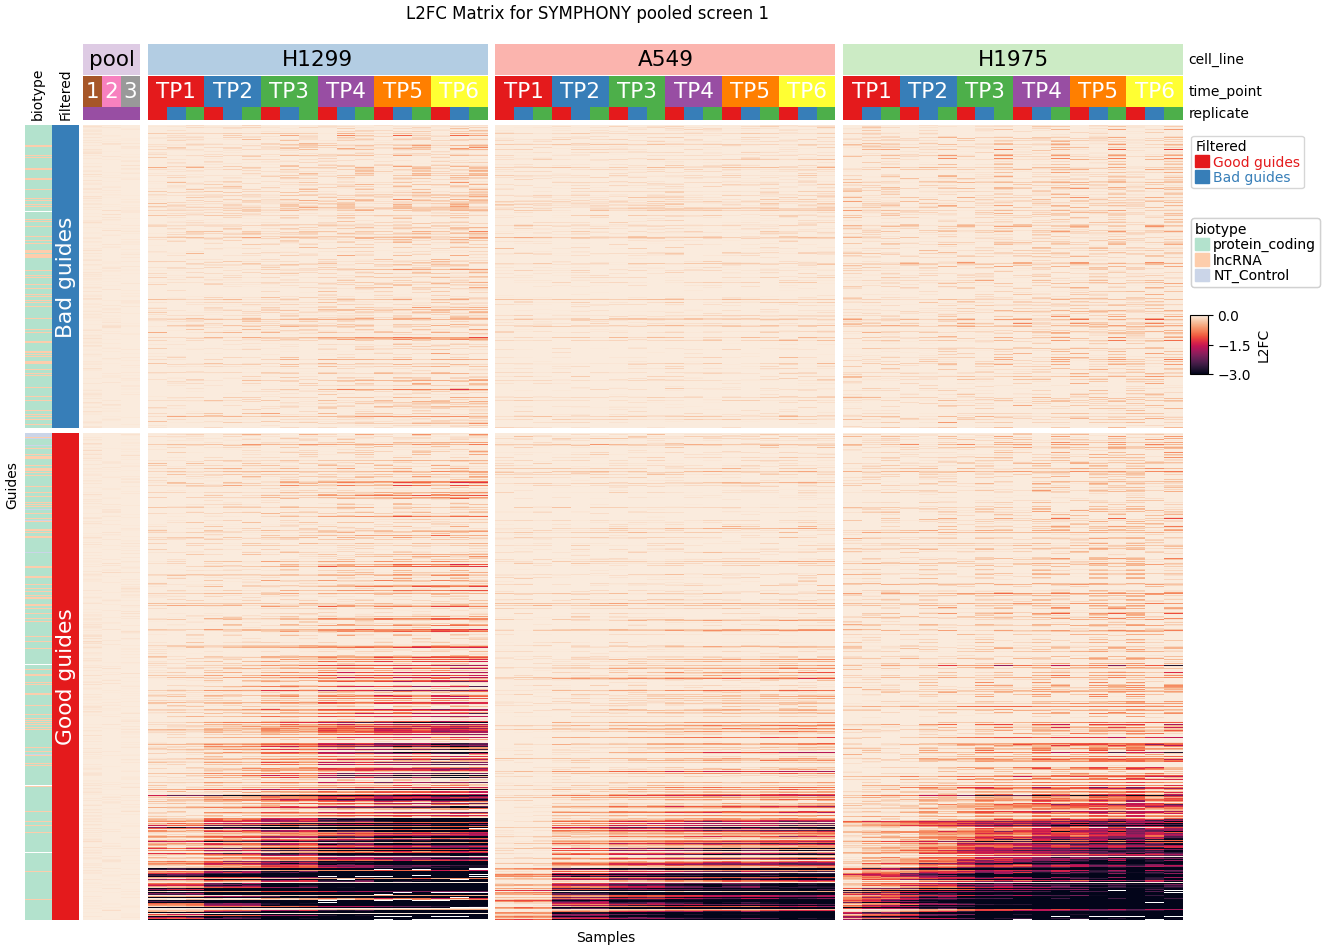

In [95]:
# visualize in heatmap
df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)

sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
sample_names_wo_pools = [x for x in sample_names if not any([p in x for p in pools])]
controls = [x for x in df.index if 'control' in x.lower()]

# First I normalize for seq-depth by bringing all NT guides to the same count
target = df.loc[controls, sample_names_wo_pools].mean().mean()  # mean of NTs in control
ist = df.loc[controls, sample_names].mean()  # mean of NTs in all
norm_factor = target / ist  # make all NT mean counts equal to those in control
ndf = df.loc[:, sample_names] * norm_factor  # normalize

# Foldchange to Pool after seq-depth normalization based on NT depth
fc = (ndf.loc[:, sample_names].T / ndf.loc[:, pools].mean(axis=1)).T  # normalize to control (pools)
l2fc = np.log2(fc)
l2fc[l2fc==-np.infty] = None

import PyComplexHeatmap as pch
df['mean_l2fc'] = l2fc.mean(axis=1)
biotype = df.sort_values(['transcript_biotype', 'mean_l2fc']).transcript_biotype
biotype = biotype[~biotype.isin(['protein_coding_CDS_not_defined', 'retained_intron'])]
is_working = all_guide_rankings.loc[:, 'summary'].loc[data.index].sort_values(by=[key, 'max_score'])[key].astype(str).map({'True': 'Good guides', 'False': 'Bad guides'})

cell_line_dict_ = {f'0{x}': y for x, y in cell_line_dict.items()}
cell_line = pd.Series({x: x.split('-')[1] for x in sample_names}).replace(cell_line_dict_)
replicate = pd.Series({x: x.split('-')[2] for x in sample_names})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] for x in sample_names})
col_order = pd.concat([cell_line, replicate, time_point], axis=1).sort_values([0, 2, 1]).index  # sort by time before replicate

# select and reorder
data = l2fc.loc[:, col_order]

top_ha = pch.HeatmapAnnotation(
    cell_line=pch.anno_simple(cell_line.loc[col_order], add_text=True, height=7, cmap='Pastel1'),
    time_point=pch.anno_simple(time_point.loc[col_order], add_text=True, height=7, cmap='Set1'),
    replicate=pch.anno_simple(replicate.loc[col_order], add_text=False),
    verbose=0, axis=1, plot_legend=False
)

left_ha = pch.HeatmapAnnotation(
    biotype=pch.anno_simple(biotype, legend=True, height=7, add_text=False, cmap='Pastel2'),
    Filtered=pch.anno_simple(is_working, legend=True, height=7, add_text=True, cmap='Set1'),
    verbose=0, axis=0, plot_legend=True
)

pl.figure(figsize=(15, 10))
cm = pch.ClusterMapPlotter(
    data=data, 
    left_annotation=left_ha, top_annotation=top_ha,
    row_cluster=False, col_cluster=False,
    row_split=is_working,
    col_split=cell_line.loc[col_order],
    col_split_gap=2, row_split_gap=1,
    label='beta', row_dendrogram=False, col_dendrogram=False,
    legend_gap=7, rasterized=True, cmap='rocket', vmin=-3, vmax=0,
    legend_kws=dict(label='L2FC'),
    xlabel="Samples", ylabel='Guides', legend_hpad=0,
    verbose=0
)
pl.suptitle('L2FC Matrix for SYMPHONY pooled screen 1', y=0.92)
# pl.savefig('../results/figures/count_matrix_l2fc_heatmap_simple.png', dpi=300)
# pl.savefig('../results/figures/count_matrix_l2fc_heatmap_simple.pdf', dpi=300)
pl.show()

In [96]:
# save results
# save results
all_guide_rankings.to_csv('../results/tables/pooled_screen_1_mageck_filtered_guides_v2.tsv', sep='\t')

## Gene Ranking

In [5]:
# The gene ranking results
filtered = True
name = '_filtered' if filtered else ''
gene_ranking = pd.read_csv(f'../results/mageck/alllines/gene_pooled_screen_1_counts{name}_mageck.gene_summary.txt', sep='\t', index_col=0)
gene_ranking = gene_ranking.reset_index().set_index(['id', 'num'])
gene_ranking.columns = pd.MultiIndex.from_arrays([
    [x.split('_vs_')[0] for x in gene_ranking.columns],
    [x.split('|')[1] for x in gene_ranking.columns],
    [x.split('|')[2] for x in gene_ranking.columns]
])

# For each sample, there are results for both pos and neg enrichment tests
# Result statistics include score, p-value, fdr, rank, "goodsgrna??", lfc
gene_ranking.head()

sym-01-01-TP6                                                      \
                     neg                                                 pos   
                   score   p-value       fdr rank goodsgrna     lfc    score   
id     num                                                                     
RAN    20   1.488200e-10  0.000005  0.000036    1        19 -4.9633  0.99998   
FBL    12   5.304500e-09  0.000005  0.000036    2        12 -6.6671  1.00000   
TMSB4X 7    9.309300e-08  0.000005  0.000036    3         7 -3.6477  1.00000   
SNHG16 10   3.598900e-07  0.000005  0.000036    4        10 -3.3369  1.00000   
EIF4A1 7    7.761900e-07  0.000005  0.000036    5         7 -4.4816  0.99999   

                              ... sym-03-03-TP6                         \
                              ...           neg                          
           p-value  fdr rank  ...           fdr rank goodsgrna     lfc   
id     num                    ...                                        
RAN    20      1.0  1.0  724  ...      0.000053    1        19 -2.3943   
FBL    12      1.0  1.0  733  ...      0.000134   25        10 -1.2671   
TMSB4X 7       1.0  1.0  732  ...      0.000053    6         7 -2.2624   
SNHG16 10      1.0  1.0  731  ...      0.000053    2        10 -2.1123   
EIF4A1 7       1.0  1.0  728  ...      0.000053    4         7 -3.9778   

                                                          
                pos                                       
              score  p-value  fdr rank goodsgrna     lfc  
id     num                                                
RAN    20   0.99972  0.99988  1.0  719         1 -2.3943  
FBL    12   0.32308  0.60271  1.0  358         2 -1.2671  
TMSB4X 7    0.99999  1.00000  1.0  732         0 -2.2624  
SNHG16 10   0.99998  1.00000  1.0  729         0 -2.1123  
EIF4A1 7    1.00000  1.00000  1.0  733         0 -3.9778  

[5 rows x 108 columns]

<Axes: ylabel='id-num'>

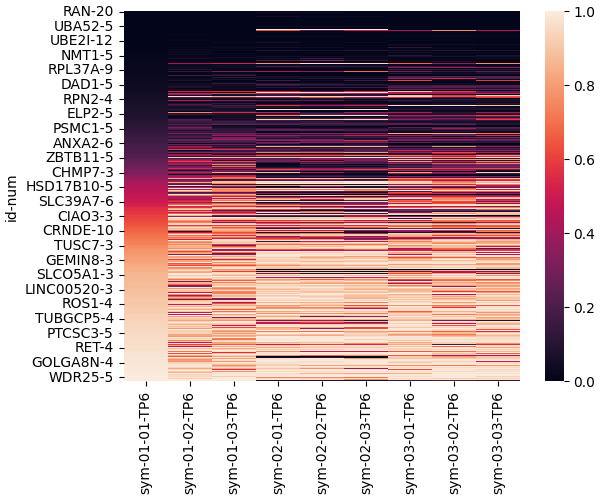

In [6]:
sns.heatmap(gene_ranking.T.loc[:, 'neg', 'score'].T)

<Axes: xlabel='lfc', ylabel='score'>

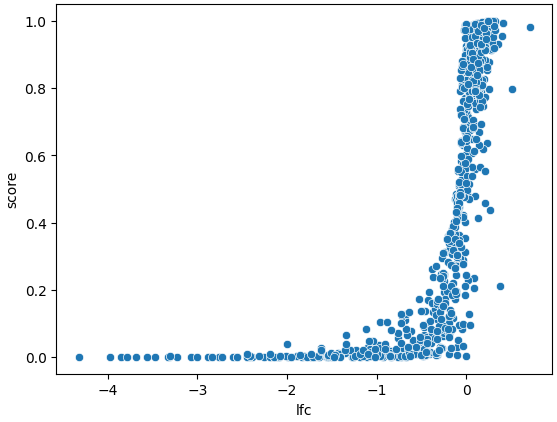

In [7]:
sns.scatterplot(data=gene_ranking.T.loc['sym-03-03-TP6', 'neg', :].T, x='lfc', y='score')

In [8]:
# unfiltered:
filtered = False
name = '_filtered' if filtered else ''
gene_ranking_ = pd.read_csv(f'../results/mageck/alllines/gene_pooled_screen_1_counts{name}_mageck.gene_summary.txt', sep='\t', index_col=0)
gene_ranking_ = gene_ranking_.reset_index().set_index(['id', 'num'])
gene_ranking_.columns = pd.MultiIndex.from_arrays([
    [x.split('_vs_')[0] for x in gene_ranking_.columns],
    [x.split('|')[1] for x in gene_ranking_.columns],
    [x.split('|')[2] for x in gene_ranking_.columns]
])

In [9]:
df_ = gene_ranking_.loc[:, (slice(None), 'neg', 'score')].mean(1).to_frame().rename(columns={0: 'MAGeCK_score'})
df_.index = df_.index.droplevel(1)
df = gene_ranking.loc[:, (slice(None), 'neg', 'score')].mean(1).to_frame().rename(columns={0: 'MAGeCK_score'})
df.index = df.index.droplevel(1)

In [10]:
tab = pd.merge(df, df_, left_index=True, right_index=True, suffixes=('_filtered', '_unfiltered'), how='outer')

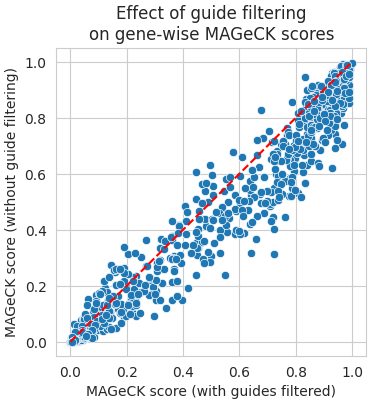

In [11]:
with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots(figsize=(4,4))
sns.scatterplot(data=tab.fillna(0), x='MAGeCK_score_filtered', y='MAGeCK_score_unfiltered')
pl.xlabel('MAGeCK score (with guides filtered)')
pl.ylabel('MAGeCK score (without guide filtering)')
pl.title('Effect of guide filtering\non gene-wise MAGeCK scores')
pl.plot([0, 1], [0, 1], color='r', linestyle='--')
pl.show()

## Transcript ranking

In [91]:
# The gene ranking results
filtered = True
name = '_filtered' if filtered else ''
gene_ranking = pd.read_csv(f'../results/mageck/alllines/transcript_pooled_screen_1_counts{name}_mageck.gene_summary.txt', sep='\t', index_col=0)
gene_ranking = gene_ranking.reset_index().set_index(['id', 'num'])
gene_ranking.columns = pd.MultiIndex.from_arrays([
    [x.split('_vs_')[0] for x in gene_ranking.columns],
    [x.split('|')[1] for x in gene_ranking.columns],
    [x.split('|')[2] for x in gene_ranking.columns]
])

# For each sample, there are results for both pos and neg enrichment tests
# Result statistics include score, p-value, fdr, rank, "goodsgrna??", lfc
gene_ranking.head()

sym-01-01-TP6                                             \
                              neg                                              
                            score   p-value       fdr rank goodsgrna     lfc   
id              num                                                            
ENST00000451311 7        0.000029  0.000005  0.000007    1         7 -3.8822   
ENST00000293831 7        0.000095  0.000005  0.000007    2         7 -4.7127   
ENST00000579618 6        0.000138  0.000005  0.000007    3         5 -4.0365   
ENST00000230050 5        0.000202  0.000005  0.000007    4         5 -4.8973   
ENST00000251453 6        0.000333  0.000005  0.000007    5         6 -6.2830   

                                                  ... sym-03-03-TP6       \
                          pos                     ...           neg        
                        score  p-value  fdr rank  ...           fdr rank   
id              num                               ...                      
ENST00000451311 7    0.999970  1.00000  1.0  640  ...      0.000007   10   
ENST00000293831 7    0.998840  1.00000  1.0  632  ...      0.000007    2   
ENST00000579618 6    0.078182  0.40137  1.0   90  ...      0.000007   43   
ENST00000230050 5    0.999800  1.00000  1.0  639  ...      0.000007    4   
ENST00000251453 6    0.999050  1.00000  1.0  636  ...      0.000007   26   

                                                                             \
                                           pos                                
                    goodsgrna     lfc    score  p-value  fdr rank goodsgrna   
id              num                                                           
ENST00000451311 7           7 -2.6592  0.99911  1.00000  1.0  634         0   
ENST00000293831 7           7 -4.3895  0.99966  1.00000  1.0  636         0   
ENST00000579618 6           4 -2.0059  0.50398  0.99995  1.0  326         0   
ENST00000230050 5           5 -4.7399  0.99968  1.00000  1.0  638         0   
ENST00000251453 6           6 -3.7407  0.99489  1.00000  1.0  620         0   

                             
                             
                        lfc  
id              num          
ENST00000451311 7   -2.6592  
ENST00000293831 7   -4.3895  
ENST00000579618 6   -2.0059  
ENST00000230050 5   -4.7399  
ENST00000251453 6   -3.7407  

[5 rows x 108 columns]

<Axes: ylabel='id-num'>

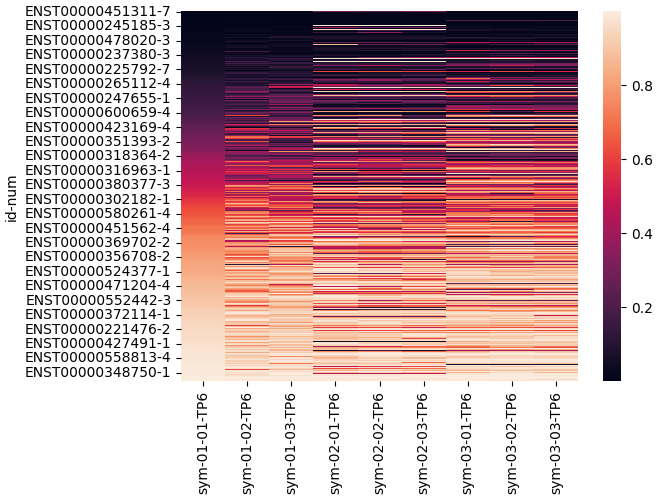

In [92]:
sns.heatmap(gene_ranking.T.loc[:, 'neg', 'score'].T)

<Axes: xlabel='lfc', ylabel='score'>

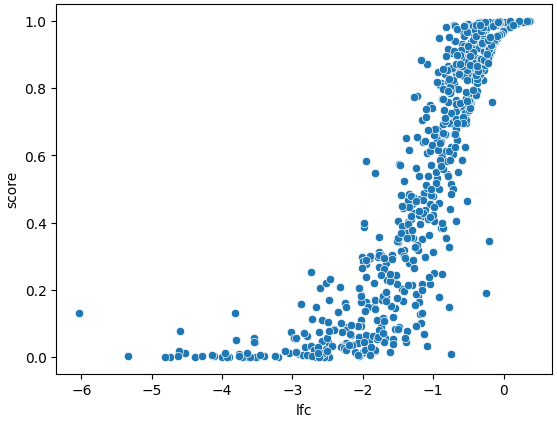

In [93]:
sns.scatterplot(data=gene_ranking.T.loc['sym-03-03-TP6', 'neg', :].T, x='lfc', y='score')